# Notebook to create Figure 4 and Figure S2

In [1]:
cran_packages <- c(
  "ggplot2", "dplyr", "glue", "RColorBrewer",
  "dendextend", "patchwork", "circlize", "rstatix"
)

for (pkg in cran_packages) {
  if (!requireNamespace(pkg, quietly = TRUE)) {
    install.packages(pkg)
  } else {
    message(glue::glue("Already installed package: {pkg}"))
  }
  library(pkg, character.only = TRUE)
}

if (!requireNamespace("BiocManager", quietly = TRUE)) {
  install.packages("BiocManager")
}
if (!requireNamespace("ComplexHeatmap", quietly = TRUE)) {
  BiocManager::install("ComplexHeatmap")
} else {
    message("Already installed package: ComplexHeatmap")
  }
library(ComplexHeatmap)

Already installed package: ggplot2

Already installed package: dplyr


Attaching package: ‘dplyr’


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union


Already installed package: glue

Already installed package: RColorBrewer

Already installed package: dendextend


---------------------
Welcome to dendextend version 1.19.1
Type citation('dendextend') for how to cite the package.

Type browseVignettes(package = 'dendextend') for the package vignette.
The github page is: https://github.com/talgalili/dendextend/

Suggestions and bug-reports can be submitted at: https://github.com/talgalili/dendextend/issues
You may ask questions at stackoverflow, use the r and dendextend tags: 
	 https://stackoverflow.com/questions/tagged/dendextend

	To suppress this message use:  suppressPackageStartupMessages(library(dendextend))
---------------------



Attaching package: ‘dendextend’

In [2]:
sequences_group <- 'bacteria_1'
path <- glue("../Results/Jaccard_distance/{sequences_group}/jaccard_results")
hyperparameter <- 'euclidean_KNN_k-25_d-0'
preferred_order <- c("TNF & DNABERT-S", "dna2vec & DNABERT-S", "HyenaDNA & DNABERT-S", "DNABERT-S & DNABERT-2", "TNF & DNABERT-2", "DNABERT-2 & dna2vec","HyenaDNA & DNABERT-2", "TNF & HyenaDNA", "dna2vec & HyenaDNA", "dna2vec & TNF")
setwd(path)

jaccard_similarities_files <- list.files(pattern = glue("*_jaccard_similarity_k-25.csv"), ignore.case = TRUE)
jaccard_similarities_files

[1] "bacteria_1_dnabert2_dna2vec_jaccard_similarity_k-25.csv" 
 [2] "bacteria_1_dnaberts_dna2vec_jaccard_similarity_k-25.csv" 
 [3] "bacteria_1_dnaberts_dnabert2_jaccard_similarity_k-25.csv"
 [4] "bacteria_1_dnaberts_tnf_jaccard_similarity_k-25.csv"     
 [5] "bacteria_1_hyenadna_dna2vec_jaccard_similarity_k-25.csv" 
 [6] "bacteria_1_hyenadna_dnabert2_jaccard_similarity_k-25.csv"
 [7] "bacteria_1_hyenadna_dnaberts_jaccard_similarity_k-25.csv"
 [8] "bacteria_1_hyenadna_tnf_jaccard_similarity_k-25.csv"     
 [9] "bacteria_1_tnf_dna2vec_jaccard_similarity_k-25.csv"      
[10] "bacteria_1_tnf_dnabert2_jaccard_similarity_k-25.csv"

In [3]:
jaccard_distances_df <- data.frame(matrix(ncol = 0, nrow = 500))

for (file in jaccard_similarities_files){
  print(file)

  jaccard_similarities <- read.table(file, header = T, sep = '\t')
  jaccard_distances <- 1 - jaccard_similarities

  models_compared <- strsplit(
    strsplit(file, paste0(sequences_group, "_"))[[1]][2],
    "_jaccard"
  )[[1]][1]
  jaccard_distances_df[,models_compared] = t(jaccard_distances)[,1]
}
rownames(jaccard_distances_df) <- paste("seq-", 1:nrow(jaccard_distances_df), sep = "")

[1] "bacteria_1_dnabert2_dna2vec_jaccard_similarity_k-25.csv"
[1] "bacteria_1_dnaberts_dna2vec_jaccard_similarity_k-25.csv"
[1] "bacteria_1_dnaberts_dnabert2_jaccard_similarity_k-25.csv"
[1] "bacteria_1_dnaberts_tnf_jaccard_similarity_k-25.csv"
[1] "bacteria_1_hyenadna_dna2vec_jaccard_similarity_k-25.csv"
[1] "bacteria_1_hyenadna_dnabert2_jaccard_similarity_k-25.csv"
[1] "bacteria_1_hyenadna_dnaberts_jaccard_similarity_k-25.csv"
[1] "bacteria_1_hyenadna_tnf_jaccard_similarity_k-25.csv"
[1] "bacteria_1_tnf_dna2vec_jaccard_similarity_k-25.csv"
[1] "bacteria_1_tnf_dnabert2_jaccard_similarity_k-25.csv"


## 1. Compute clustering

In [4]:
distance_matrix_jacc_comp_seq = dist(jaccard_distances_df)
h_jacc_comp_seq = hclust(distance_matrix_jacc_comp_seq, method = "ward.D2")
clusters_jacc <- cutree(h_jacc_comp_seq, k = 7)

In [5]:
cluster_color_map <- setNames(
  c("#ffcc00", "#99da60", "#ff914d", "#5170ff", "#e2a9f1", "#c94268", "#903087"),
  1:7
)
my_palette_jacc <- rev(colorRampPalette(brewer.pal(9, "RdBu"))(200))
breaks_seq_jacc <- seq(min(jaccard_distances_df), max(jaccard_distances_df), length.out = 201)

In [6]:
name_map_jacc <- c(
  "tnf_dna2vec" = "dna2vec & TNF",
  "tnf_dnabert2" = "TNF & DNABERT-2",
  "dnabert2_dna2vec" = "DNABERT-2 & dna2vec",
  "dnaberts_tnf" = "TNF & DNABERT-S",
  "dnaberts_dna2vec" = "dna2vec & DNABERT-S",
  "dnaberts_dnabert2" = "DNABERT-S & DNABERT-2",
  "hyenadna_tnf" = "TNF & HyenaDNA",
  "hyenadna_dna2vec" = "dna2vec & HyenaDNA",
  "hyenadna_dnabert2" = "HyenaDNA & DNABERT-2",
  "hyenadna_dnaberts" = "HyenaDNA & DNABERT-S"
)

In [7]:
colnames(jaccard_distances_df) <- name_map_jacc[colnames(jaccard_distances_df)]
mat_jaccard <- as.matrix(jaccard_distances_df)[, preferred_order]

## 2. Display the heatmap

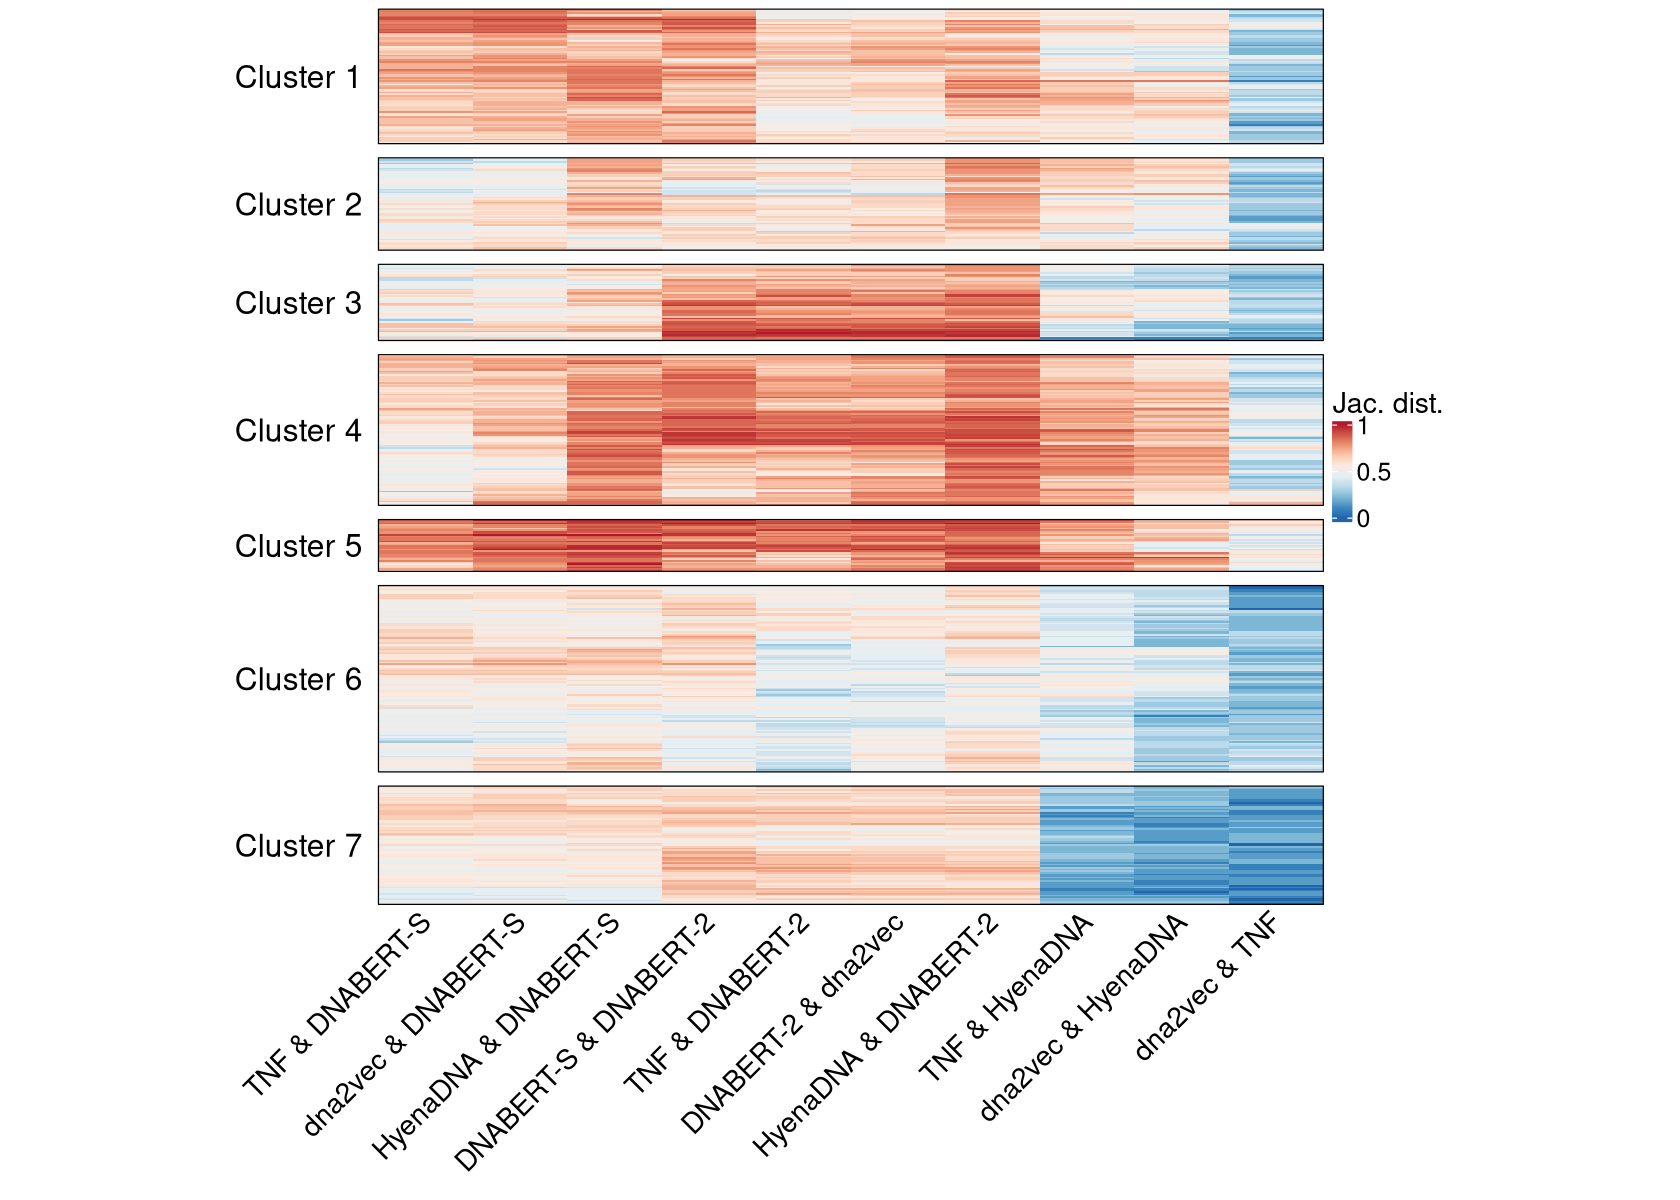

In [8]:
options(repr.plot.width = 14, repr.plot.height = 10)

ht_main <- Heatmap(
  mat_jaccard,
  name = "Jac. dist.",
  cluster_rows = rev(h_jacc_comp_seq),
  cluster_columns = FALSE,
  show_row_names = FALSE,
  col = colorRamp2(
    breaks_seq_jacc[seq(1, 201, length.out = 10)],
    my_palette_jacc[seq(1, 200, length.out = 10)]
  ),
  row_split = 7,
  row_gap = unit(3, "mm"),
  border = TRUE,
  column_names_rot = 45,
  column_names_gp = gpar(fontsize = 17),
  width = unit(20, "cm"),
  show_row_dend = FALSE,
  row_title = "Cluster %s",
  row_title_rot = 0,
  row_title_side = "left",
  row_title_gp = gpar(fontsize = 19),
  heatmap_legend_param = list(
    title_gp = gpar(fontsize = 17),
    labels_gp = gpar(fontsize = 15)
  )
)
ht_main

## 3. Add biological features to the previous heatmap

In [10]:
sequences_annotations <- read.table(glue("../../../../Data/Sequences/{sequences_group}_sequences.csv"), header = T, sep=',')
colnames(sequences_annotations)[colnames(sequences_annotations) == 'seq_id'] <- 'seq_id_first'
sequences_annotations$seq_id <- paste("seq-", 1:nrow(sequences_annotations), sep = "")
colnames(sequences_annotations)[colnames(sequences_annotations) == 'nb_orfs'] <- 'ORF'
colnames(sequences_annotations)[colnames(sequences_annotations) == 'per.GC'] <- 'GC %'
colnames(sequences_annotations)[colnames(sequences_annotations) == 'coding_pct'] <- 'CDS %'
colnames(sequences_annotations)[colnames(sequences_annotations) == 'coding_pct_plus'] <- 'C+/n %'
colnames(sequences_annotations)[colnames(sequences_annotations) == 'coding_pct_minus'] <- 'C-/n %'
colnames(sequences_annotations)[colnames(sequences_annotations) == 'pct_plus_in_coding_pct'] <- 'C+/C %'
colnames(sequences_annotations)[colnames(sequences_annotations) == 'Shannon.Entropy'] <- 'Ent.'

In [11]:
clusters_df <- as.data.frame(clusters_jacc)
clusters_df$seq_id <- paste("seq-", 1:nrow(sequences_annotations), sep = "")
colnames(clusters_df) <- c('Clusters', 'seq_id')
annot_clusters_jaccard_df <- sequences_annotations %>% left_join(clusters_df, by = "seq_id")
annot_clusters_jaccard_df$Clusters <- factor(annot_clusters_jaccard_df$Clusters)

In [12]:
vars <- c("CDS %", "GC %", 'Ent.')

In [13]:
seq_matrix <- annot_clusters_jaccard_df %>%
  arrange(match(seq_id, rownames(mat_jaccard))) %>%
  select(all_of(vars)) %>%
  as.matrix()

rownames(seq_matrix) <- annot_clusters_jaccard_df %>%
  arrange(match(seq_id, rownames(mat_jaccard))) %>%
  pull(seq_id)

In [14]:
seq_matrix_clipped <- apply(seq_matrix, 2, function(x) {
  q1 <- quantile(x, 0.25)
  q3 <- quantile(x, 0.75)
  iqr <- q3 - q1
  lower <- q1 - 1.5 * iqr
  upper <- q3 + 1.5 * iqr
  pmin(pmax(x, lower), upper)
})
rownames(seq_matrix_clipped) <- rownames(seq_matrix)

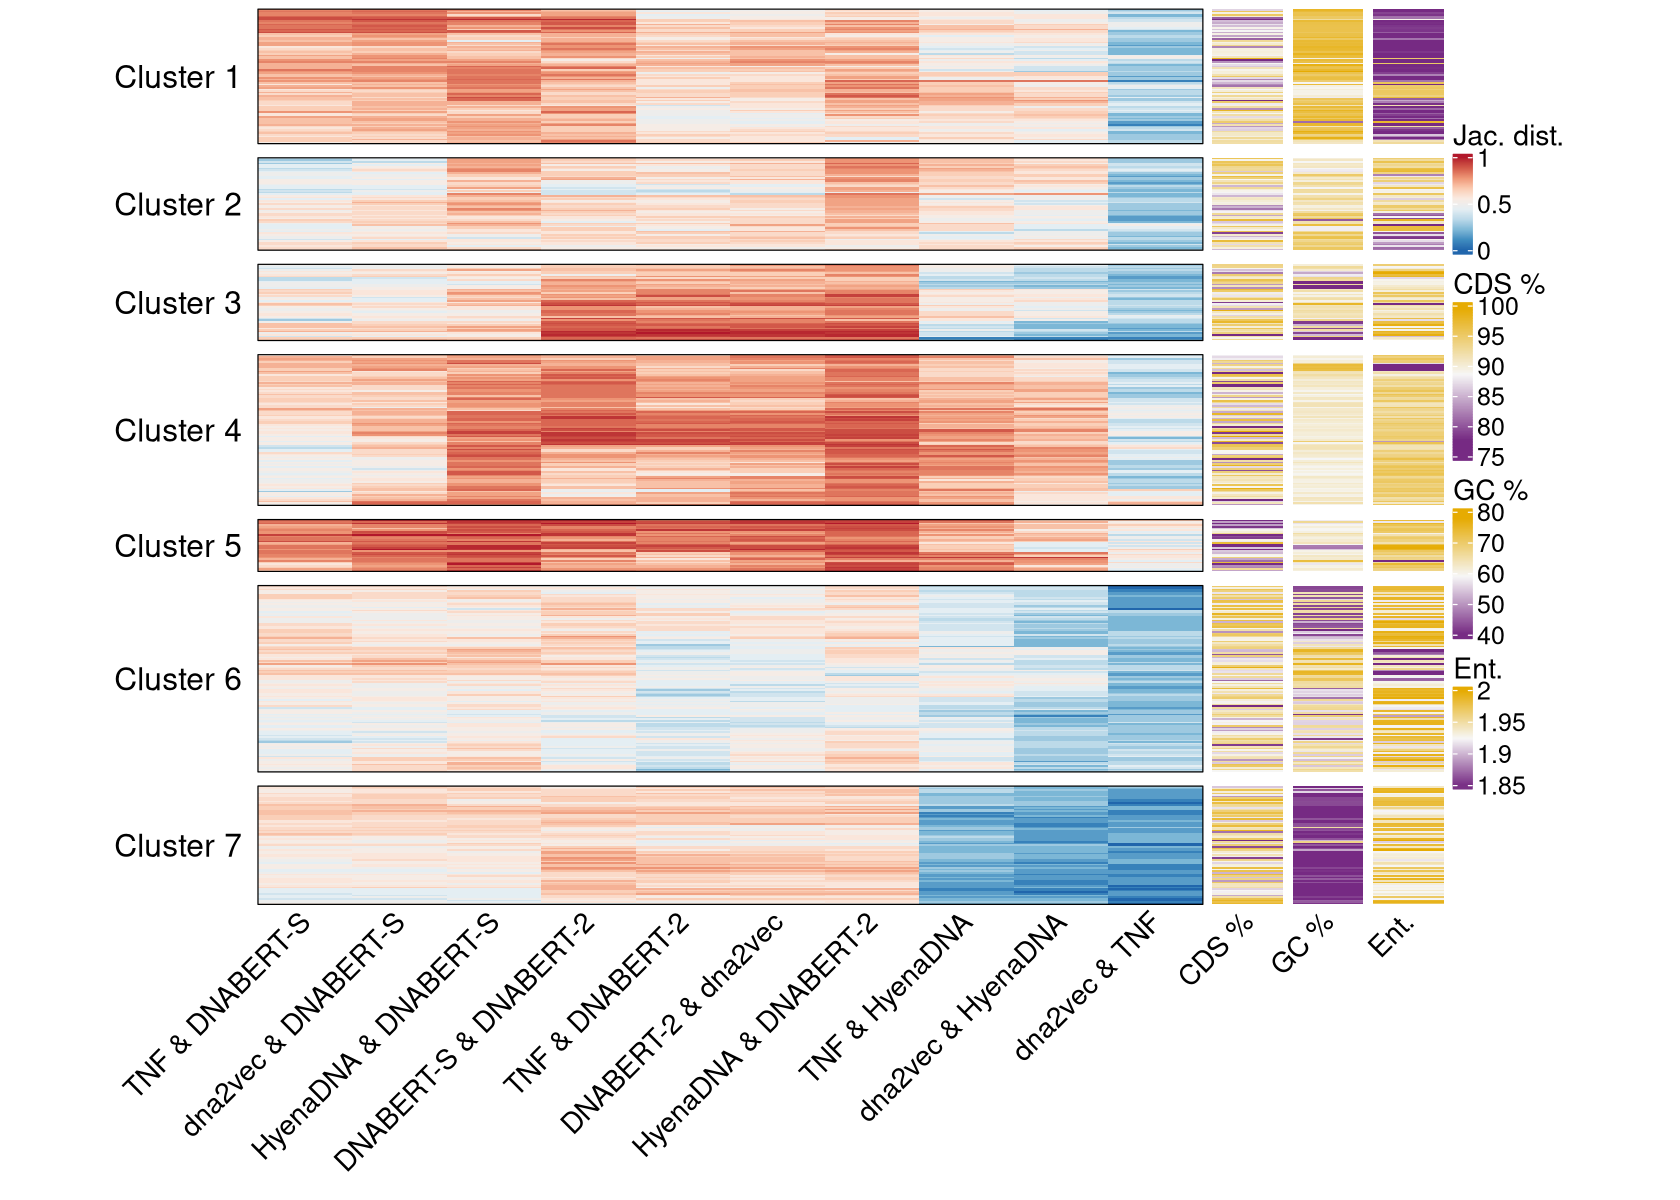

In [15]:
ht_list <- lapply(vars, function(v) {
  mat <- matrix(seq_matrix_clipped[, v], ncol = 1)
  rownames(mat) <- rownames(seq_matrix_clipped)
  colnames(mat) <- v

  Heatmap(
    mat,
    name = v,
    cluster_rows = FALSE,
    cluster_columns = FALSE,
    show_row_names = FALSE,
    column_names_rot = 45,
    column_names_gp = gpar(fontsize = 17),
    col = colorRampPalette(c("#762a83", "#f7f7f7", "#e6ab02"))(100),
    width = unit(1.5, "cm"),
    heatmap_legend_param = list(
      title_gp = gpar(fontsize = 17),
      labels_gp = gpar(fontsize = 15)
    )
  )
})

ht_combined2 <- Reduce("+", ht_list)
draw(ht_main + ht_combined2)

In [16]:
svg(glue("../../../Plots/{sequences_group}_jaccard_heatmaps_figure_4.svg"), width = 16, height = 14) #12.5 et 12 pour 3 vars
draw(ht_main + ht_combined2)
dev.off()

agg_record_c3e54538e8b6 
                      2

## 4. Statistical test (Kruskal-Wallis and Dunn tests)

  new_cluster old_cluster
1           1           1
2           2           2
3           3           6
4           4           3
5           5           4
6           6           5
7           7           7


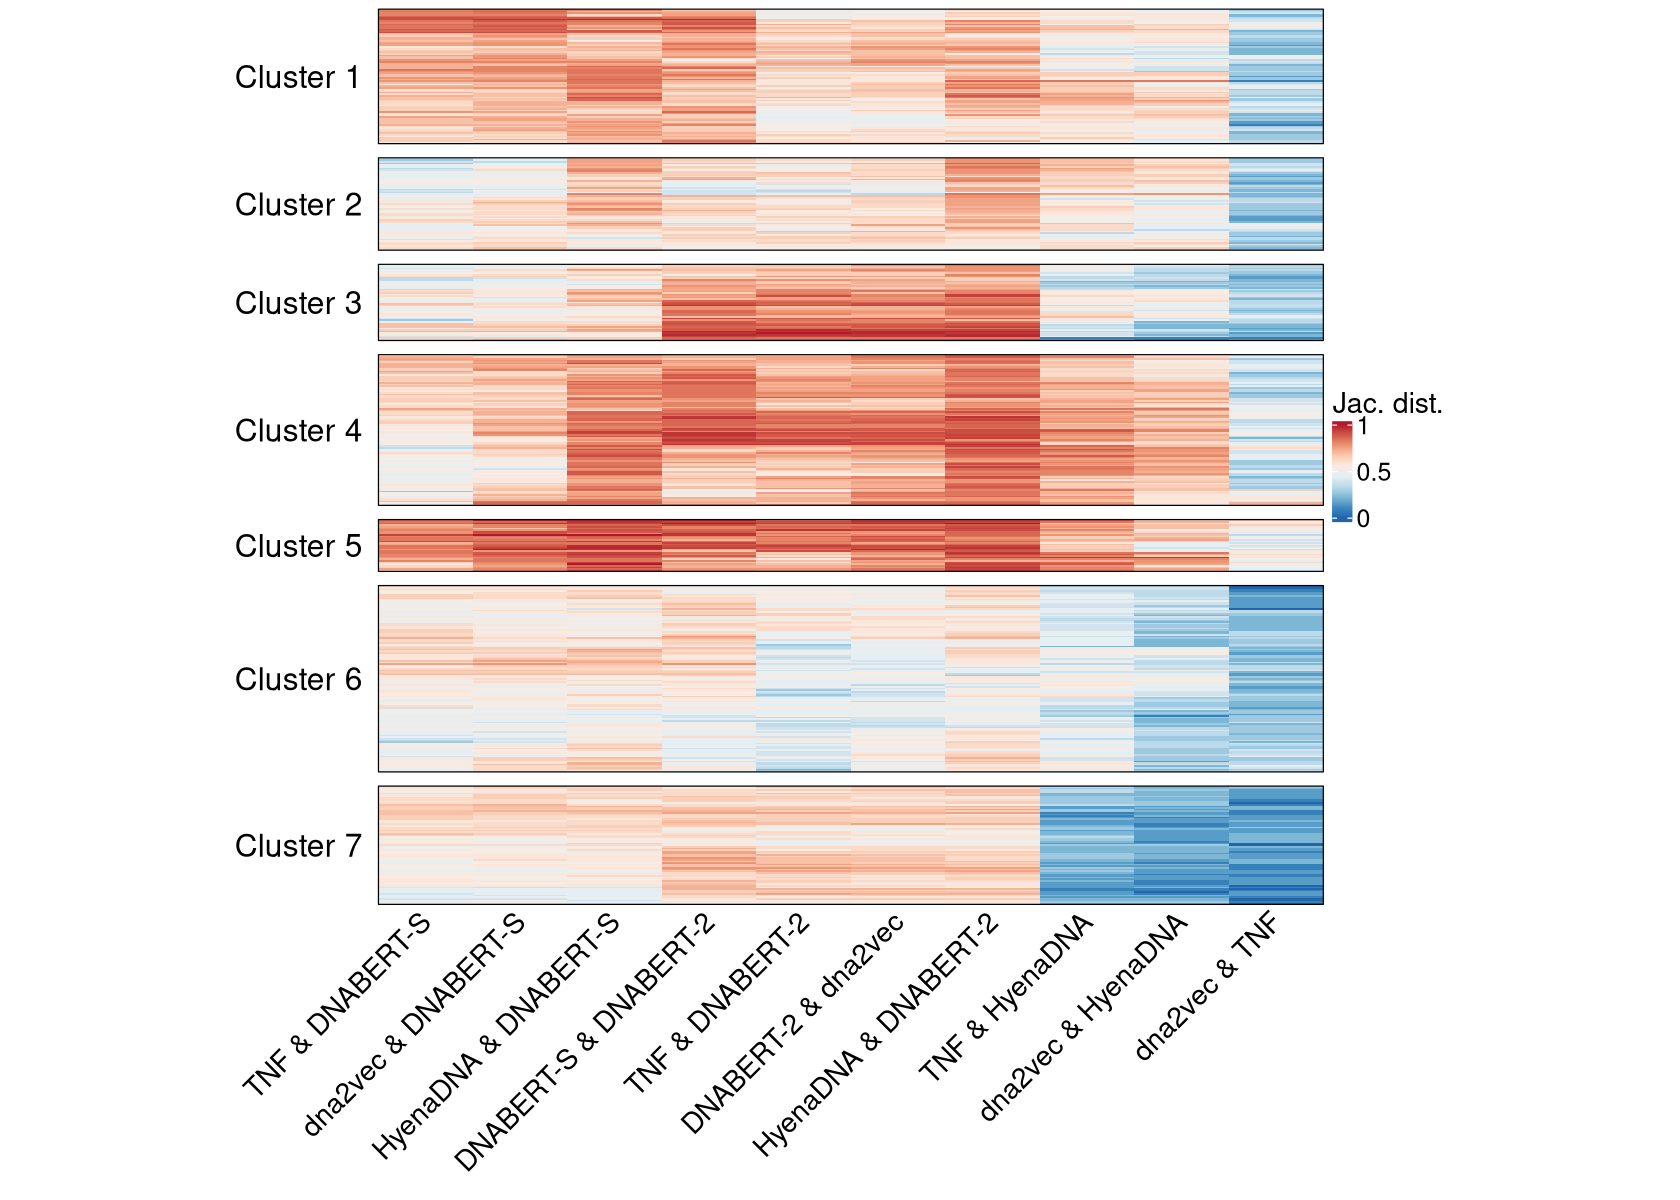

In [17]:
ht_drawn <- draw(ht_main)
row_order_list <- row_order(ht_drawn)

correspondance <- data.frame(
  new_cluster = seq_along(row_order_list),
  old_cluster = sapply(row_order_list, function(idx) {
    unique(clusters_jacc[idx])
  })
)
print(correspondance)

In [18]:
annot_clusters_jaccard_df <- annot_clusters_jaccard_df %>%
  mutate(Clusters_num = as.numeric(as.character(Clusters))) %>%
  left_join(correspondance, by = c("Clusters_num" = "old_cluster")) %>%
  mutate(Clusters_heatmap = factor(new_cluster)) %>%
  select(-new_cluster, -Clusters_num)

In [19]:
vars <- c("ORF", "CDS %", "C+/n %", "C-/n %", "C+/C %", "GC %", "Ent.")

annot_clusters_jaccard_df$Clusters <- as.factor(annot_clusters_jaccard_df$Clusters)

kruskal_results <- list()
dunn_results_raw <- list()

for (v in vars) {
  
  cat("\n============================\n")
  cat("Tested feature :", v, "\n")
  cat("============================\n")
  
  formula_str <- paste0("`", v, "` ~ Clusters_heatmap")
  formula_obj <- as.formula(formula_str)
  
  # Kruskal-Wallis
  kw <- kruskal_test(annot_clusters_jaccard_df, formula_obj)
  kruskal_results[[v]] <- kw
  print(kw)
  
  # Dunn
  dt <- dunn_test(
    annot_clusters_jaccard_df,
    formula_obj,
    p.adjust.method = "none" 
  )
  
  dunn_results_raw[[v]] <- dt
}

dunn_all <- bind_rows(dunn_results_raw, .id = "variable")
dunn_all$p.adj.global <- p.adjust(dunn_all$p, method = "bonferroni")


dunn_all <- dunn_all %>%
  mutate(signif_global = case_when(
    p.adj.global < 0.001 ~ "****",
    p.adj.global < 0.01  ~ "***",
    p.adj.global < 0.05  ~ "**",
    p.adj.global < 0.1   ~ "*",
    TRUE ~ "ns"
  ))

print(dunn_all, n = Inf)


Tested feature : ORF 
# A tibble: 1 × 6
  .y.       n statistic    df      p method        
* <chr> <int>     <dbl> <int>  <dbl> <chr>         
1 ORF     500      13.7     6 0.0330 Kruskal-Wallis

Tested feature : CDS % 
# A tibble: 1 × 6
  .y.       n statistic    df           p method        
* <chr> <int>     <dbl> <int>       <dbl> <chr>         
1 CDS %   500      38.6     6 0.000000861 Kruskal-Wallis

Tested feature : C+/n % 
# A tibble: 1 × 6
  .y.        n statistic    df     p method        
* <chr>  <int>     <dbl> <int> <dbl> <chr>         
1 C+/n %   500      7.71     6 0.260 Kruskal-Wallis

Tested feature : C-/n % 
# A tibble: 1 × 6
  .y.        n statistic    df      p method        
* <chr>  <int>     <dbl> <int>  <dbl> <chr>         
1 C-/n %   500      11.6     6 0.0714 Kruskal-Wallis

Tested feature : C+/C % 
# A tibble: 1 × 6
  .y.        n statistic    df     p method        
* <chr>  <int>     <dbl> <int> <dbl> <chr>         
1 C+/C %   500      8.55     6 0.200 K

In [20]:
plot_dunn_matrix <- function(dunn_all, var_test, cluster_var = "Clusters_heatmap", 
                              p_col = "p.adj.global") {
  
  dt <- dunn_all %>% filter(variable == var_test)
  
  all_clusters <- levels(annot_clusters_jaccard_df[[cluster_var]])
  
  dt_sym <- bind_rows(
    dt %>% select(group1, group2, p.adj = all_of(p_col)),
    dt %>% select(group1 = group2, group2 = group1, p.adj = all_of(p_col))
  )
  
  diag_df <- data.frame(group1 = all_clusters, group2 = all_clusters, p.adj = NA)
  
  dt_sym <- bind_rows(dt_sym, diag_df) %>%
    mutate(significant = case_when(
      is.na(p.adj) ~ " ",
      p.adj < 0.05 ~ "Significant",
      TRUE ~ "Not significant"
    ))
  
  ggplot(dt_sym, aes(x = group1, y = group2, fill = significant)) +
    geom_tile(color = "white", linewidth = 0.5) +
    geom_text(aes(label = ifelse(is.na(p.adj), "", sprintf("%.3f", p.adj))), size = 4) +
    scale_fill_manual(values = c(
      "Significant" = "#ea95ff",
      "Not significant" = "#b9e2ff",
      " " = "#ffffff"
    )) +
    scale_x_discrete(limits = all_clusters, position = "top") + 
    scale_y_discrete(limits = rev(all_clusters)) +
    labs(title = paste("Biological feature —", var_test), x = "Clusters", y = "Clusters", fill = "Dunn test p-values:") +
    theme_minimal(base_size = 14) +
    theme(axis.text.x = element_text(hjust = 1), panel.grid = element_blank())
}

In [21]:
p1 <- plot_dunn_matrix(dunn_all, "GC %")

p2 <- plot_dunn_matrix(dunn_all, "CDS %")

p3 <- plot_dunn_matrix(dunn_all, "Ent.")

p4 <- plot_dunn_matrix(dunn_all, "ORF")

p5 <- plot_dunn_matrix(dunn_all, "C+/n %")

p6 <- plot_dunn_matrix(dunn_all, "C-/n %")

p7 <- plot_dunn_matrix(dunn_all, "C+/C %")

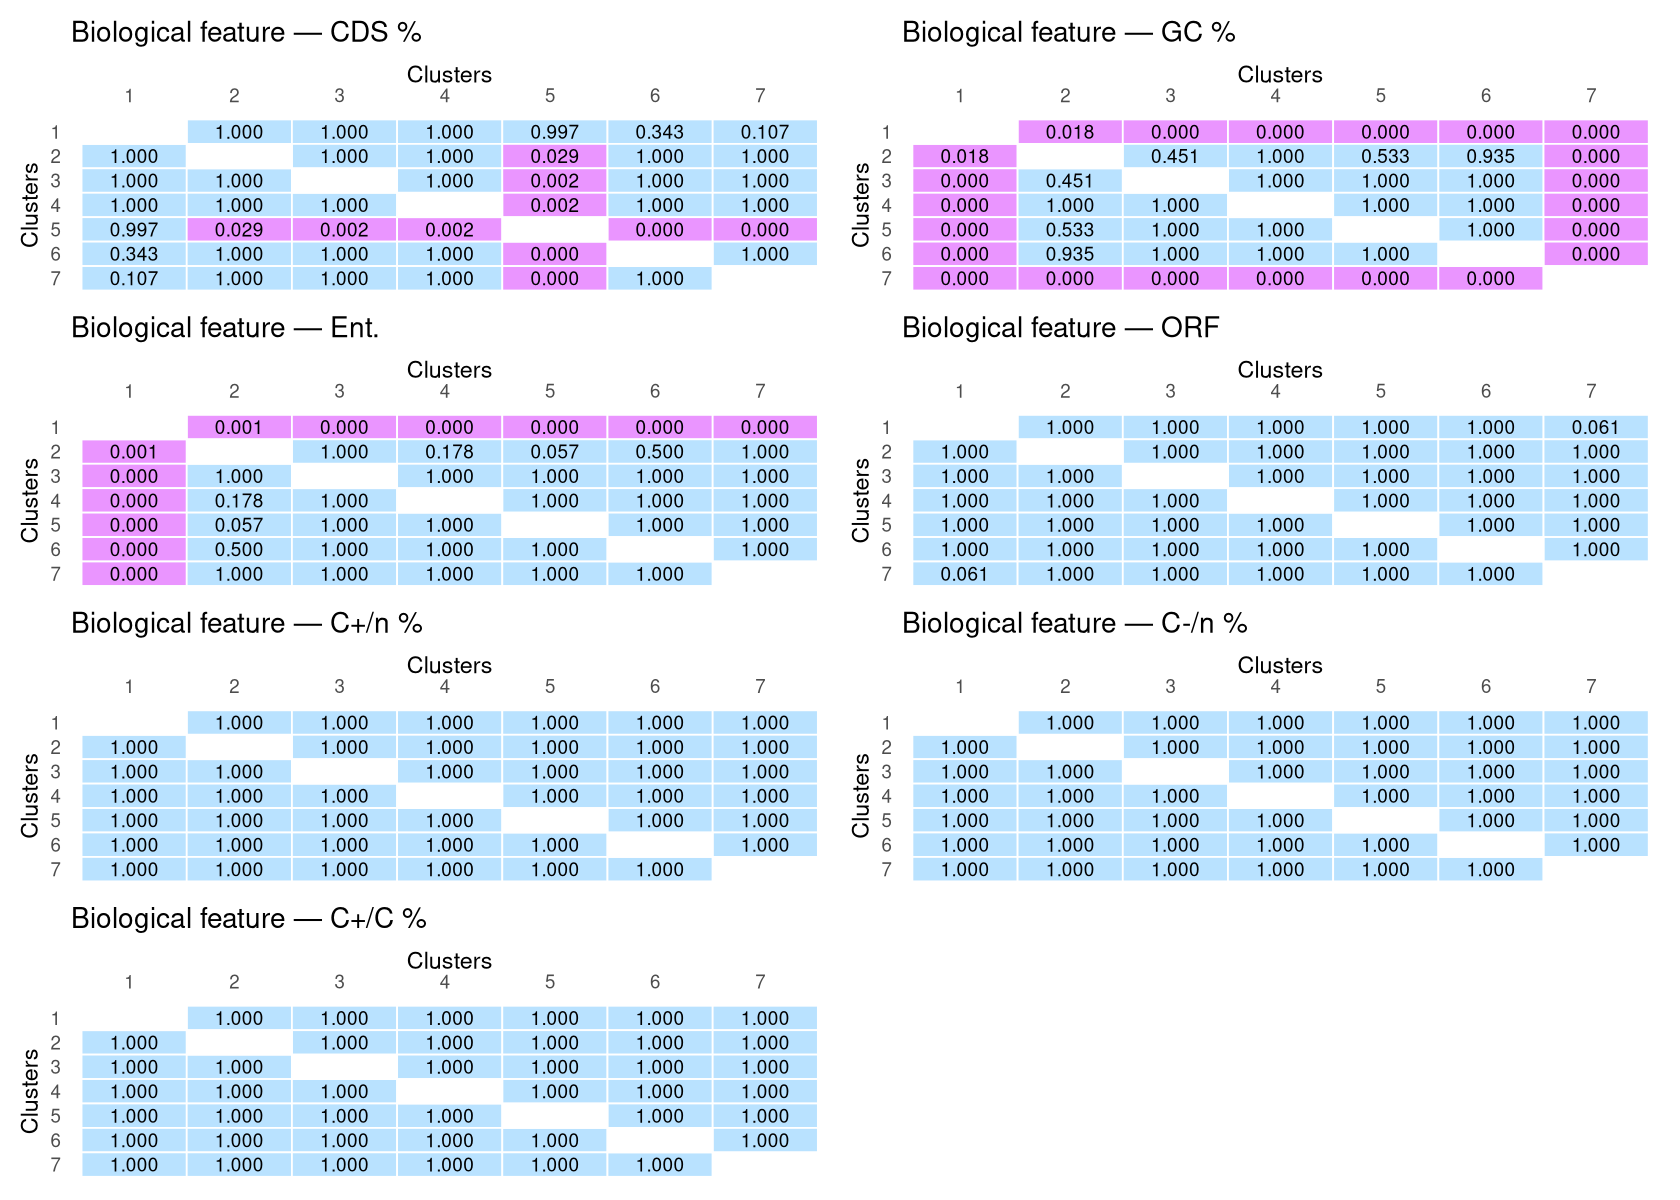

In [22]:
p <- p2 / p1 / p3 / p4 / p5 / p6 / p7 +

  plot_layout(ncol = 2, guides = "collect") &
  theme(legend.position = "none")
p

In [24]:
ggsave(glue("../../../Plots/{sequences_group}_jaccard_test_dunn_figure_S2.png"), p, 
       width = 12, height = 14, dpi = 500)

In [25]:
write.csv(annot_clusters_jaccard_df[, c('seq_id', 'Clusters_heatmap')], 'jaccard_clusters.csv', row.names = FALSE)